In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("AB_NYC_2019.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
df.shape

(48895, 16)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [7]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [10]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [11]:
df.isnull().sum().sum()

np.int64(20141)

In [12]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Working copy created successfully!")

Working copy created successfully!


In [13]:
# Remove unnecessary columns
df_clean.drop(columns=["id", "last_review"], inplace=True)

print("Unnecessary columns removed!")

Unnecessary columns removed!


In [14]:
# Calculate mean of reviews_per_month
mean_reviews = df_clean["reviews_per_month"].mean()

# Fill numerical missing values using mean
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(mean_reviews)

# Fill missing text values
df_clean["name"] = df_clean["name"].fillna("Unknown")
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")

print("Missing values handled successfully!")
print("Mean reviews per month:", mean_reviews)

Missing values handled successfully!
Mean reviews per month: 1.3732214298586616


In [15]:
# Check missing values in every column
df_clean.isnull().sum()

name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [16]:
# Count all remaining missing values
total_missing = df_clean.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


In [17]:

# Create a new column called price_category

df_clean["price_category"] = pd.cut(
    df_clean["price"],
    bins=[-1, 100, 200, 500, float("inf")],
    labels=["Budget", "Moderate", "Premium", "Luxury"]
)

print("Price categories created successfully!")


Price categories created successfully!


In [18]:

df_clean[["price", "price_category"]].head(10)


,price,price_category
0,149,Moderate
1,225,Premium
2,150,Moderate
3,89,Budget
4,80,Budget
5,200,Moderate
6,60,Budget
7,79,Budget
8,79,Budget
9,150,Moderate


In [19]:

df_clean["price_category"].value_counts()


price_category
Budget      23928
Moderate    16583
Premium      7340
Luxury       1044
Name: count, dtype: int64

In [20]:
# Calculate average Airbnb price

average_price = df_clean["price"].mean()

print("Average Airbnb price:", average_price)

Average Airbnb price: 152.7206871868289


In [21]:
# Count different room types

room_counts = df_clean["room_type"].value_counts()

print(room_counts)

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


In [22]:
# Count Airbnb listings in each neighbourhood

neighbourhood_counts = df_clean["neighbourhood_group"].value_counts()

print(neighbourhood_counts)

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


In [23]:
# Calculate average price by neighbourhood

neighbourhood_prices = df_clean.groupby(
    "neighbourhood_group"
)["price"].mean().sort_values(ascending=False)

print(neighbourhood_prices)

neighbourhood_group
Manhattan        196.875814
Brooklyn         124.383207
Staten Island    114.812332
Queens            99.517649
Bronx             87.496792
Name: price, dtype: float64


In [24]:
# Count listings in each price category

price_counts = df_clean["price_category"].value_counts()

print(price_counts)

price_category
Budget      23928
Moderate    16583
Premium      7340
Luxury       1044
Name: count, dtype: int64


In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


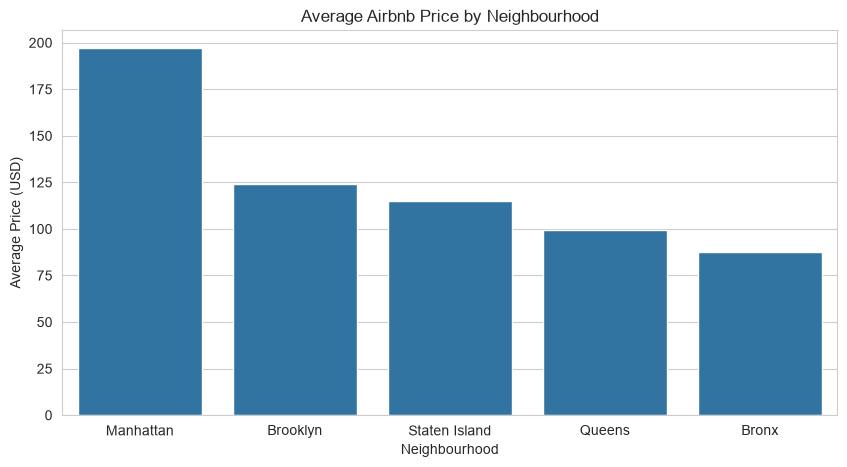

In [26]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=neighbourhood_prices.index,
    y=neighbourhood_prices.values
)

plt.title("Average Airbnb Price by Neighbourhood")
plt.xlabel("Neighbourhood")
plt.ylabel("Average Price (USD)")

plt.show()


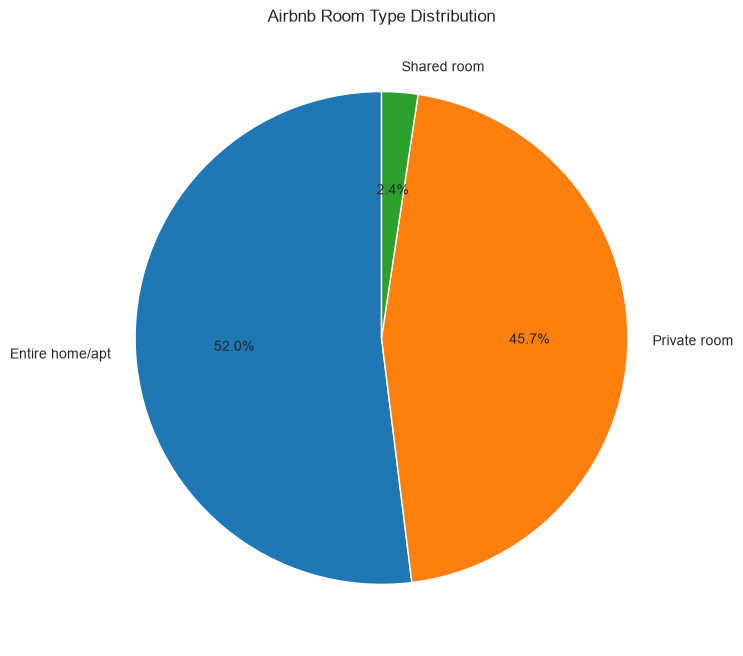

In [27]:

# Count different room types

room_counts = df_clean["room_type"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    room_counts,
    labels=room_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Airbnb Room Type Distribution")

plt.show()


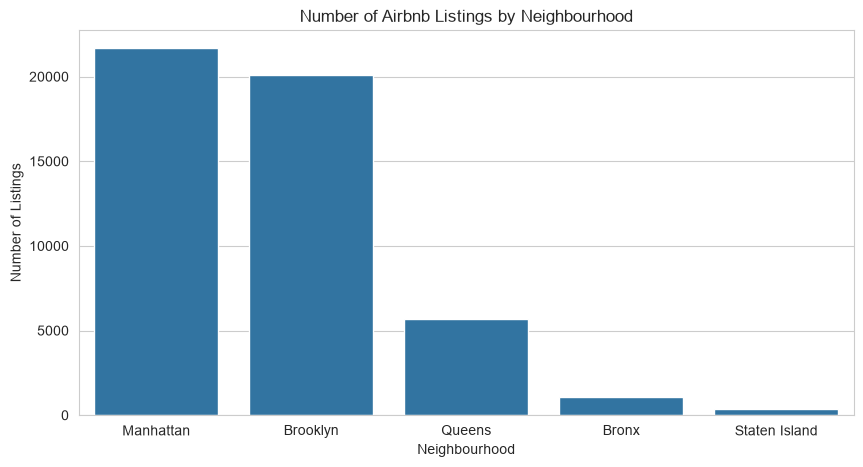

In [28]:

# Count Airbnb listings in each neighbourhood

neighbourhood_counts = df_clean["neighbourhood_group"].value_counts()

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=neighbourhood_counts.index,
    y=neighbourhood_counts.values
)

plt.title("Number of Airbnb Listings by Neighbourhood")
plt.xlabel("Neighbourhood")
plt.ylabel("Number of Listings")

plt.show()


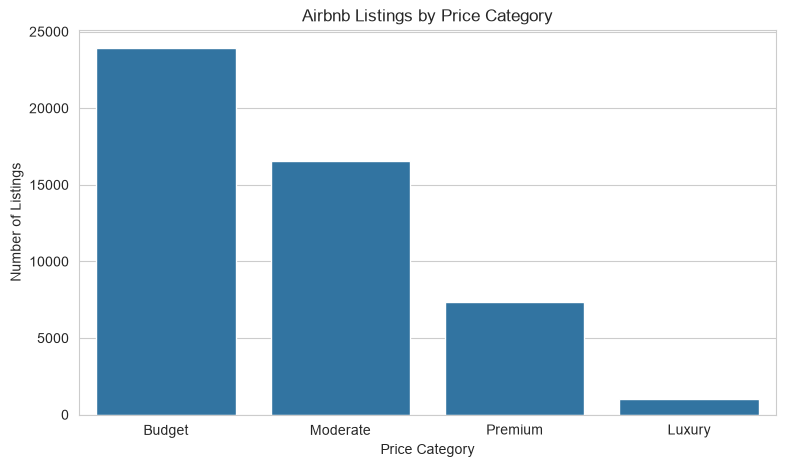

In [29]:

# Count listings in each price category

price_counts = df_clean["price_category"].value_counts()

# Create bar chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x=price_counts.index,
    y=price_counts.values
)

plt.title("Airbnb Listings by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Listings")

plt.show()
